In [82]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is NOT available")

CUDA available: True
GPU: Tesla T4


In [83]:
!pip install -q segmentation-models-pytorch

In [84]:
import os
import zipfile

from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
%matplotlib inline

import albumentations as albu
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn

import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

import segmentation_models_pytorch as smp

# **Step 1 — Load DATA:**

In [85]:
from google.colab import drive
drive.mount('/content/drive')


# =========================
# Paths
# =========================

DATA_DIR = "/content/drive/MyDrive"

CLOUD_DATA_ZIP = os.path.join(DATA_DIR, "cloud-data.zip")
TEST_ZIP = os.path.join(DATA_DIR, "test_images.zip")


# =========================
# Extract training data
# =========================

TRAIN_DATA_DIR = "/content/cloud_data"

with zipfile.ZipFile(CLOUD_DATA_ZIP, "r") as zip_ref:
    zip_ref.extractall(TRAIN_DATA_DIR)


# =========================
# Extract test data
# =========================

TEST_DATA_DIR = "/content/test_images"

with zipfile.ZipFile(TEST_ZIP, "r") as zip_ref:
    zip_ref.extractall(TEST_DATA_DIR)


# =========================
# Actual data paths
# =========================

TRAIN_IMAGES_DIR = "/content/cloud_data/data/train_images"
TRAIN_CSV = "/content/cloud_data/data/train.csv"
TEST_IMAGES_DIR = "/content/test_images/test_images"

print("Train images exists:", os.path.exists(TRAIN_IMAGES_DIR))
print("Train CSV exists:", os.path.exists(TRAIN_CSV))
print("Test images exists:", os.path.exists(TEST_IMAGES_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train images exists: True
Train CSV exists: True
Test images exists: True


# Load Dataset → Split Image Labels → Check Image Resolution

In [86]:
# =========================
# Load training CSV
# =========================

train = pd.read_csv(TRAIN_CSV)

print("Train CSV shape:", train.shape)
print("\nColumns:")
print(train.columns.tolist())

print("\nFirst 5 rows:")
display(train.head())


# =========================
# Split Image_Label
# =========================

train[["Image_id", "Cloud_Type"]] = train["Image_Label"].str.split(
    "_", expand=True
)

train = train[["Image_id", "Cloud_Type", "EncodedPixels"]]

print("\nAfter splitting:")
display(train.head())


# =========================
# Check basic dataset information
# =========================

print("\nNumber of annotation rows:", len(train))
print("Number of unique images:", train["Image_id"].nunique())

print("\nCloud type counts:")
print(train["Cloud_Type"].value_counts())


# =========================
# Check image resolution
# =========================

image_files = [
    f for f in os.listdir(TRAIN_IMAGES_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\nNumber of training image files:", len(image_files))

# Read first image
first_image_path = os.path.join(TRAIN_IMAGES_DIR, image_files[0])

first_image = Image.open(first_image_path)

print("First image:", image_files[0])
print("Image size (width, height):", first_image.size)
print("Image mode:", first_image.mode)


# =========================
# Verify resolution across dataset
# =========================

sizes = {}

for filename in image_files:
    with Image.open(os.path.join(TRAIN_IMAGES_DIR, filename)) as img:
        sizes[img.size] = sizes.get(img.size, 0) + 1

print("\nImage resolutions:")
for size, count in sizes.items():
    print(size, "->", count, "images")

Train CSV shape: (22184, 2)

Columns:
['Image_Label', 'EncodedPixels']

First 5 rows:


,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...



After splitting:


,Image_id,Cloud_Type,EncodedPixels
0,0011165.jpg,Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg,Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg,Gravel,NaN
3,0011165.jpg,Sugar,NaN
4,002be4f.jpg,Fish,17668 241 18051 242 18435 242 18819 242 19203 ...



Number of annotation rows: 22184
Number of unique images: 5546

Cloud type counts:
Cloud_Type
Fish      5546
Flower    5546
Gravel    5546
Sugar     5546
Name: count, dtype: int64

Number of training image files: 5546
First image: 195f280.jpg
Image size (width, height): (576, 384)
Image mode: RGB

Image resolutions:
(576, 384) -> 5546 images


In [71]:
# =========================
# Decode RLE
# =========================

def rle_decode(rle, shape=(384, 576)):
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if pd.isna(rle):
        return mask.reshape(shape)

    numbers = list(map(int, rle.split()))

    starts = numbers[0::2]
    lengths = numbers[1::2]

    for start, length in zip(starts, lengths):
        start -= 1
        mask[start:start + length] = 1

    return mask.reshape(shape, order="F")
  # ===========================
  #create_multichannel_mask
  # ========================

def create_multichannel_mask(image_id, df):
    """
    Create a 4-channel mask for one image.
    Returns: numpy array of shape (H, W, 4) with dtype float32
    """

    # Get image dimensions from the global constants
    height = 384
    width = 576

    mask = np.zeros(
        (height, width, 4),
        dtype=np.float32
    )

    image_rows = df[
        df["Image_id"] == image_id
    ]

    class_map = {
        "Fish": 0,
        "Flower": 1,
        "Gravel": 2,
        "Sugar": 3
    }

    for _, row in image_rows.iterrows():

        if pd.notna(row["EncodedPixels"]):

            channel = class_map[
                row["Cloud_Type"]
            ]

            binary_mask = rle_decode(
                row["EncodedPixels"],
                shape=(height, width)
            )

            mask[:, :, channel] = binary_mask

    return mask

In [72]:
def get_train_transforms():
    return albu.Compose([
        albu.HorizontalFlip(p=0.5),
        albu.VerticalFlip(p=0.5),

        albu.ShiftScaleRotate(
            shift_limit=0.1,
            scale_limit=0.15,
            rotate_limit=20,
            border_mode=0,
            p=0.5
        ),

        albu.OneOf([
            albu.RandomBrightnessContrast(p=1),
            albu.RandomGamma(p=1),
            albu.CLAHE(p=1),
        ], p=0.5),

        albu.OneOf([
            albu.GaussNoise(p=1),
            albu.GaussianBlur(p=1),
            albu.MotionBlur(p=1),
        ], p=0.3),

        albu.Resize(
            height=384,
            width=576
        ),

        albu.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),

        ToTensorV2()
    ])


def get_valid_transforms():
    return albu.Compose([
        albu.Resize(
            height=384,
            width=576
        ),

        albu.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),

        ToTensorV2()
    ])

In [73]:
class CloudDataset(Dataset):
    def __init__(self, df, image_ids, images_dir, transforms=None, is_test=False):
        self.df = df
        self.image_ids = list(image_ids)
        self.images_dir = images_dir
        self.transforms = transforms
        self.is_test = is_test

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image_path = os.path.join(self.images_dir, image_id)

        # Load image
        image = np.array(Image.open(image_path).convert("RGB"))

        if self.is_test:
            if self.transforms:
                augmented = self.transforms(image=image)
                image = augmented["image"]
            return image, image_id

        # Ground truth mask (H, W, 4)
        mask = create_multichannel_mask(image_id, self.df)

        # Apply transforms
        if self.transforms:
            augmented = self.transforms(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        # Convert mask to (4, H, W)
        if isinstance(mask, np.ndarray):
            mask = torch.from_numpy(mask).permute(2, 0, 1).float()
        else:
            mask = mask.permute(2, 0, 1).float()

        return image, mask, image_id

In [74]:
image_ids = train["Image_id"].unique()

train_ids, valid_ids = train_test_split(
    image_ids,
    test_size=0.1,
    random_state=42
)

train_dataset = CloudDataset(
    df=train,
    image_ids=train_ids,
    images_dir=TRAIN_IMAGES_DIR,
    transforms=get_train_transforms(),
    is_test=False
)

valid_dataset = CloudDataset(
    df=train,
    image_ids=valid_ids,
    images_dir=TRAIN_IMAGES_DIR,
    transforms=get_valid_transforms(),
    is_test=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

Train images: 4991
Validation images: 555
Train batches: 624
Validation batches: 70


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


#DiceBCELoss

In [75]:
class DiceBCELoss(nn.Module):
    def __init__(self, weight_dice=0.7, weight_bce=0.3, smooth=1e-5):
        super().__init__()
        self.weight_dice = weight_dice
        self.weight_bce = weight_bce
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        # BCE
        bce_loss = self.bce(logits, targets)

        # Dice
        probs = torch.sigmoid(logits)
        dims = (2, 3)
        intersection = (probs * targets).sum(dims)
        cardinality = probs.sum(dims) + targets.sum(dims)
        dice = (2. * intersection + self.smooth) / (cardinality + self.smooth)
        dice_loss = 1 - dice.mean()

        return self.weight_bce * bce_loss + self.weight_dice * dice_loss

# Model + Training setup

In [76]:
# =========================
# Device
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =========================
# Model
# =========================
model = smp.Unet(
    encoder_name="resnet34",        # good balance of speed/accuracy
    encoder_weights="imagenet",
    in_channels=3,
    classes=4,
    activation=None                 # we use BCEWithLogits → no activation
)
model = model.to(device)

# =========================
# Loss & Optimizer
# =========================
criterion = DiceBCELoss(weight_dice=0.7, weight_bce=0.3)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
)

Using device: cuda


# Simple Training Loop (for testing)

In [77]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)

# Dice Score

In [78]:
def dice_score(logits, targets, threshold=0.5, smooth=1e-5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    dims = (2, 3)
    intersection = (preds * targets).sum(dims)
    cardinality = preds.sum(dims) + targets.sum(dims)
    dice = (2. * intersection + smooth) / (cardinality + smooth)
    return dice.mean().item()

# Training & Validation function

In [79]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_dice = 0.0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = criterion(logits, masks)
        dice = dice_score(logits, masks)

        running_loss += loss.item()
        running_dice += dice

    return running_loss / len(loader), running_dice / len(loader)

In [80]:
def train_model(
    model,
    train_loader,
    valid_loader,
    optimizer,
    scheduler,
    criterion,
    device,
    epochs=30,
    early_stopping_patience=5
):
    best_dice = 0.0
    patience_counter = 0
    history = {"train_loss": [], "val_loss": [], "val_dice": []}

    for epoch in range(1, epochs + 1):
        print(f"\nEpoch {epoch}/{epochs}")
        print("-" * 40)

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_dice = validate(model, valid_loader, criterion, device)

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        print(f"Train Loss : {train_loss:.4f}")
        print(f"Val Loss   : {val_loss:.4f}")
        print(f"Val Dice   : {val_dice:.4f}")

        if val_dice > best_dice:
            best_dice = val_dice
            patience_counter = 0
            torch.save(model.state_dict(), "best_model.pth")
            print(f"→ Best model saved (Dice: {best_dice:.4f})")
        else:
            patience_counter += 1
            print(f"→ No improvement ({patience_counter}/{early_stopping_patience})")

            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break

    print(f"\nTraining finished. Best Dice: {best_dice:.4f}")
    return history

# Model Training

In [81]:
history = train_model(
    model=model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    criterion=criterion,
    device=device,
    epochs=30,
    early_stopping_patience=5
)


Epoch 1/30
----------------------------------------
Train Loss : 0.6678
Val Loss   : 0.6229
Val Dice   : 0.4320
→ Best model saved (Dice: 0.4320)

Epoch 2/30
----------------------------------------
Train Loss : 0.6190
Val Loss   : 0.6041
Val Dice   : 0.4452
→ Best model saved (Dice: 0.4452)

Epoch 3/30
----------------------------------------
Train Loss : 0.6093
Val Loss   : 0.5965
Val Dice   : 0.4456
→ Best model saved (Dice: 0.4456)

Epoch 4/30
----------------------------------------
Train Loss : 0.6050
Val Loss   : 0.5966
Val Dice   : 0.4795
→ Best model saved (Dice: 0.4795)

Epoch 5/30
----------------------------------------
Train Loss : 0.6010
Val Loss   : 0.5926
Val Dice   : 0.4591
→ No improvement (1/5)

Epoch 6/30
----------------------------------------
Train Loss : 0.5987
Val Loss   : 0.5907
Val Dice   : 0.4522
→ No improvement (2/5)

Epoch 7/30
----------------------------------------
Train Loss : 0.5961
Val Loss   : 0.5867
Val Dice   : 0.4872
→ Best model saved (Dice: 0

In [87]:
print(os.path.exists("best_model.pth"))

True


In [88]:
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4,
    activation=None
)

model = model.to(device)

model.load_state_dict(
    torch.load("best_model.pth", map_location=device)
)

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [89]:
@torch.no_grad()
def evaluate_model(model, loader, device, threshold=0.5):
    model.eval()

    total_dice = 0.0
    num_batches = 0

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        dice = dice_score(logits, masks, threshold=threshold)

        total_dice += dice
        num_batches += 1

    return total_dice / num_batches


val_dice = evaluate_model(
    model,
    valid_loader,
    device,
    threshold=0.5
)

print(f"Validation Dice Score: {val_dice:.4f}")

Validation Dice Score: 0.4877


In [90]:
@torch.no_grad()
def per_class_dice(model, loader, device, threshold=0.5):
    model.eval()

    intersection = torch.zeros(4, device=device)
    cardinality = torch.zeros(4, device=device)

    for images, masks, _ in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()

        intersection += (preds * masks).sum(dim=(0, 2, 3))
        cardinality += preds.sum(dim=(0, 2, 3)) + masks.sum(dim=(0, 2, 3))

    dice = (2 * intersection + 1e-5) / (cardinality + 1e-5)

    return dice.cpu().numpy()


class_names = ["Fish", "Flower", "Gravel", "Sugar"]

class_dice = per_class_dice(
    model,
    valid_loader,
    device,
    threshold=0.5
)

for name, score in zip(class_names, class_dice):
    print(f"{name}: {score:.4f}")

Fish: 0.5385
Flower: 0.6691
Gravel: 0.5688
Sugar: 0.6130


In [94]:
per_class_dice = {
    "Fish": 0.5385,
    "Flower": 0.6691,
    "Gravel": 0.5688,
    "Sugar": 0.6130
}

overall_dice = np.mean(list(per_class_dice.values()))

print(f"Overall Dice Score: {overall_dice:.4f}")

Overall Dice Score: 0.5974


In [95]:
class_names = ["Fish", "Flower", "Gravel", "Sugar"]

model.eval()

with torch.no_grad():
    images, masks, image_ids = next(iter(valid_loader))

    images = images.to(device)

    logits = model(images)
    probs = torch.sigmoid(logits)
    preds = (probs > 0.5).float()

print("Images:", images.shape)
print("Ground Truth:", masks.shape)
print("Prediction:", preds.shape)

Images: torch.Size([8, 3, 384, 576])
Ground Truth: torch.Size([8, 4, 384, 576])
Prediction: torch.Size([8, 4, 384, 576])


# Training History — Loss & Dice

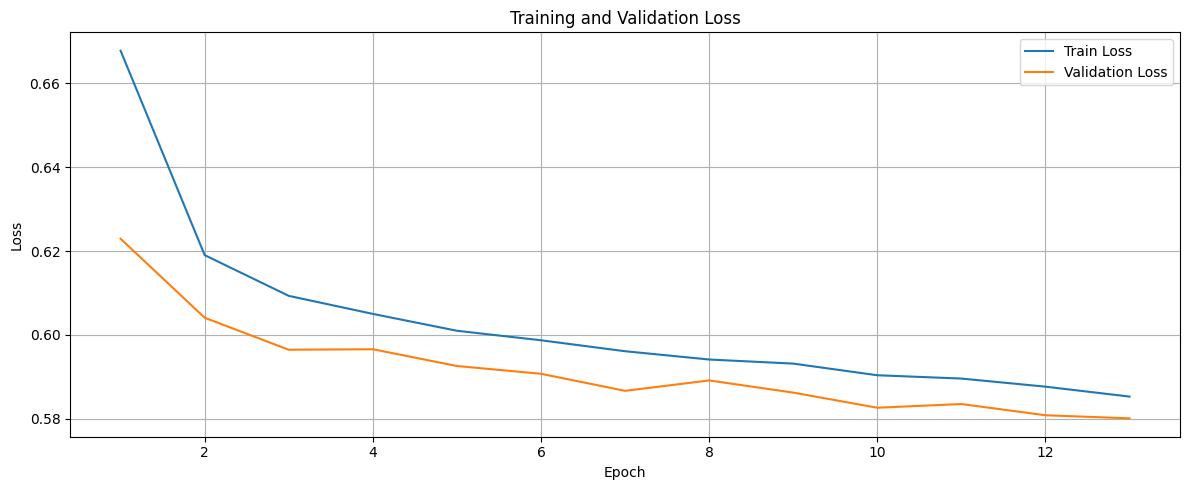

In [101]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Validation Dice Score

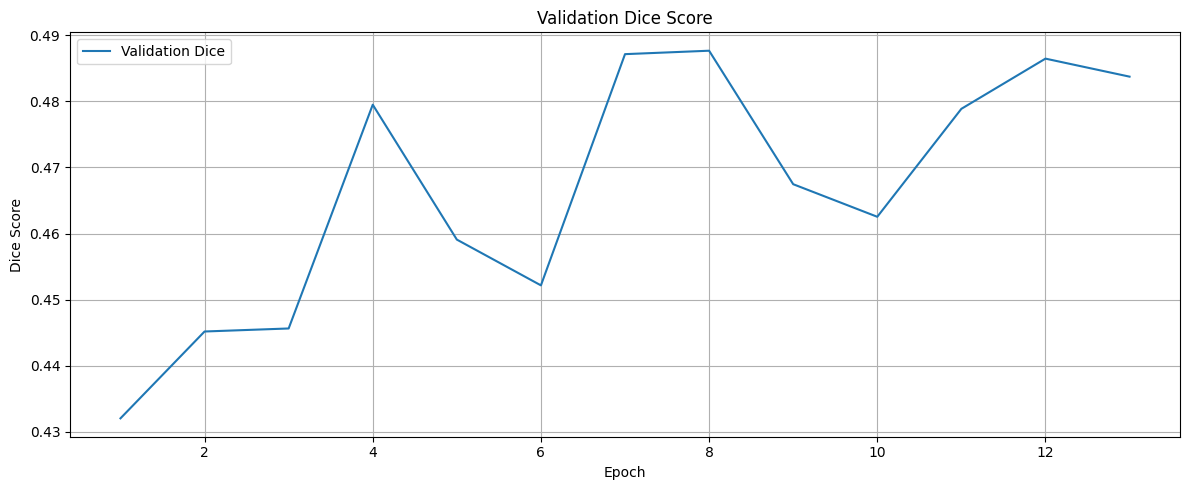

In [102]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["val_dice"]) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    epochs,
    history["val_dice"],
    label="Validation Dice"
)

plt.title("Validation Dice Score")
plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [103]:
model.eval()

val_loss, val_dice = validate(
    model,
    valid_loader,
    criterion,
    device
)

print("\nValidation performance")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Dice: {val_dice:.4f}")


Validation performance
Validation Loss: 0.5891
Validation Dice: 0.4877


# Test Set Prediction

In [105]:
import os
import cv2
import numpy as np
import torch

TEST_DIR = TEST_IMAGES_DIR

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

THRESHOLDS = np.array([
    0.5,
    0.5,
    0.5,
    0.5
])

# Get test image names
test_images = [
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Randomly choose 4 images
random_images = np.random.choice(
    test_images,
    size=4,
    replace=False
)

print("Selected images:")
print(random_images)

# Load images
X_test = []

for image_name in random_images:

    image_path = os.path.join(
        TEST_DIR,
        image_name
    )

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load: {image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (576, 384)
    )

    image = image.astype(np.float32) / 255.0

    # ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = (image - mean) / std

    # HWC → CHW
    image = image.transpose(2, 0, 1)

    X_test.append(image)

X_test = np.array(
    X_test,
    dtype=np.float32
)

print("Input shape:", X_test.shape)

# Convert to PyTorch tensor
X_test = torch.tensor(X_test).to(device)

# Prediction
model.eval()

with torch.no_grad():
    logits = model(X_test)
    pred_prob = torch.sigmoid(logits)

# Convert probabilities to masks
thresholds = torch.tensor(
    THRESHOLDS,
    dtype=torch.float32,
    device=device
).view(1, 4, 1, 1)

pred_mask = (
    pred_prob > thresholds
).float()

print("Prediction shape:", pred_mask.shape)

Selected images:
['76ff6b6.jpg' 'ea32456.jpg' '68773cd.jpg' 'c86343c.jpg']
Input shape: (4, 3, 384, 576)
Prediction shape: torch.Size([4, 4, 384, 576])


# Test Prediction Visualization

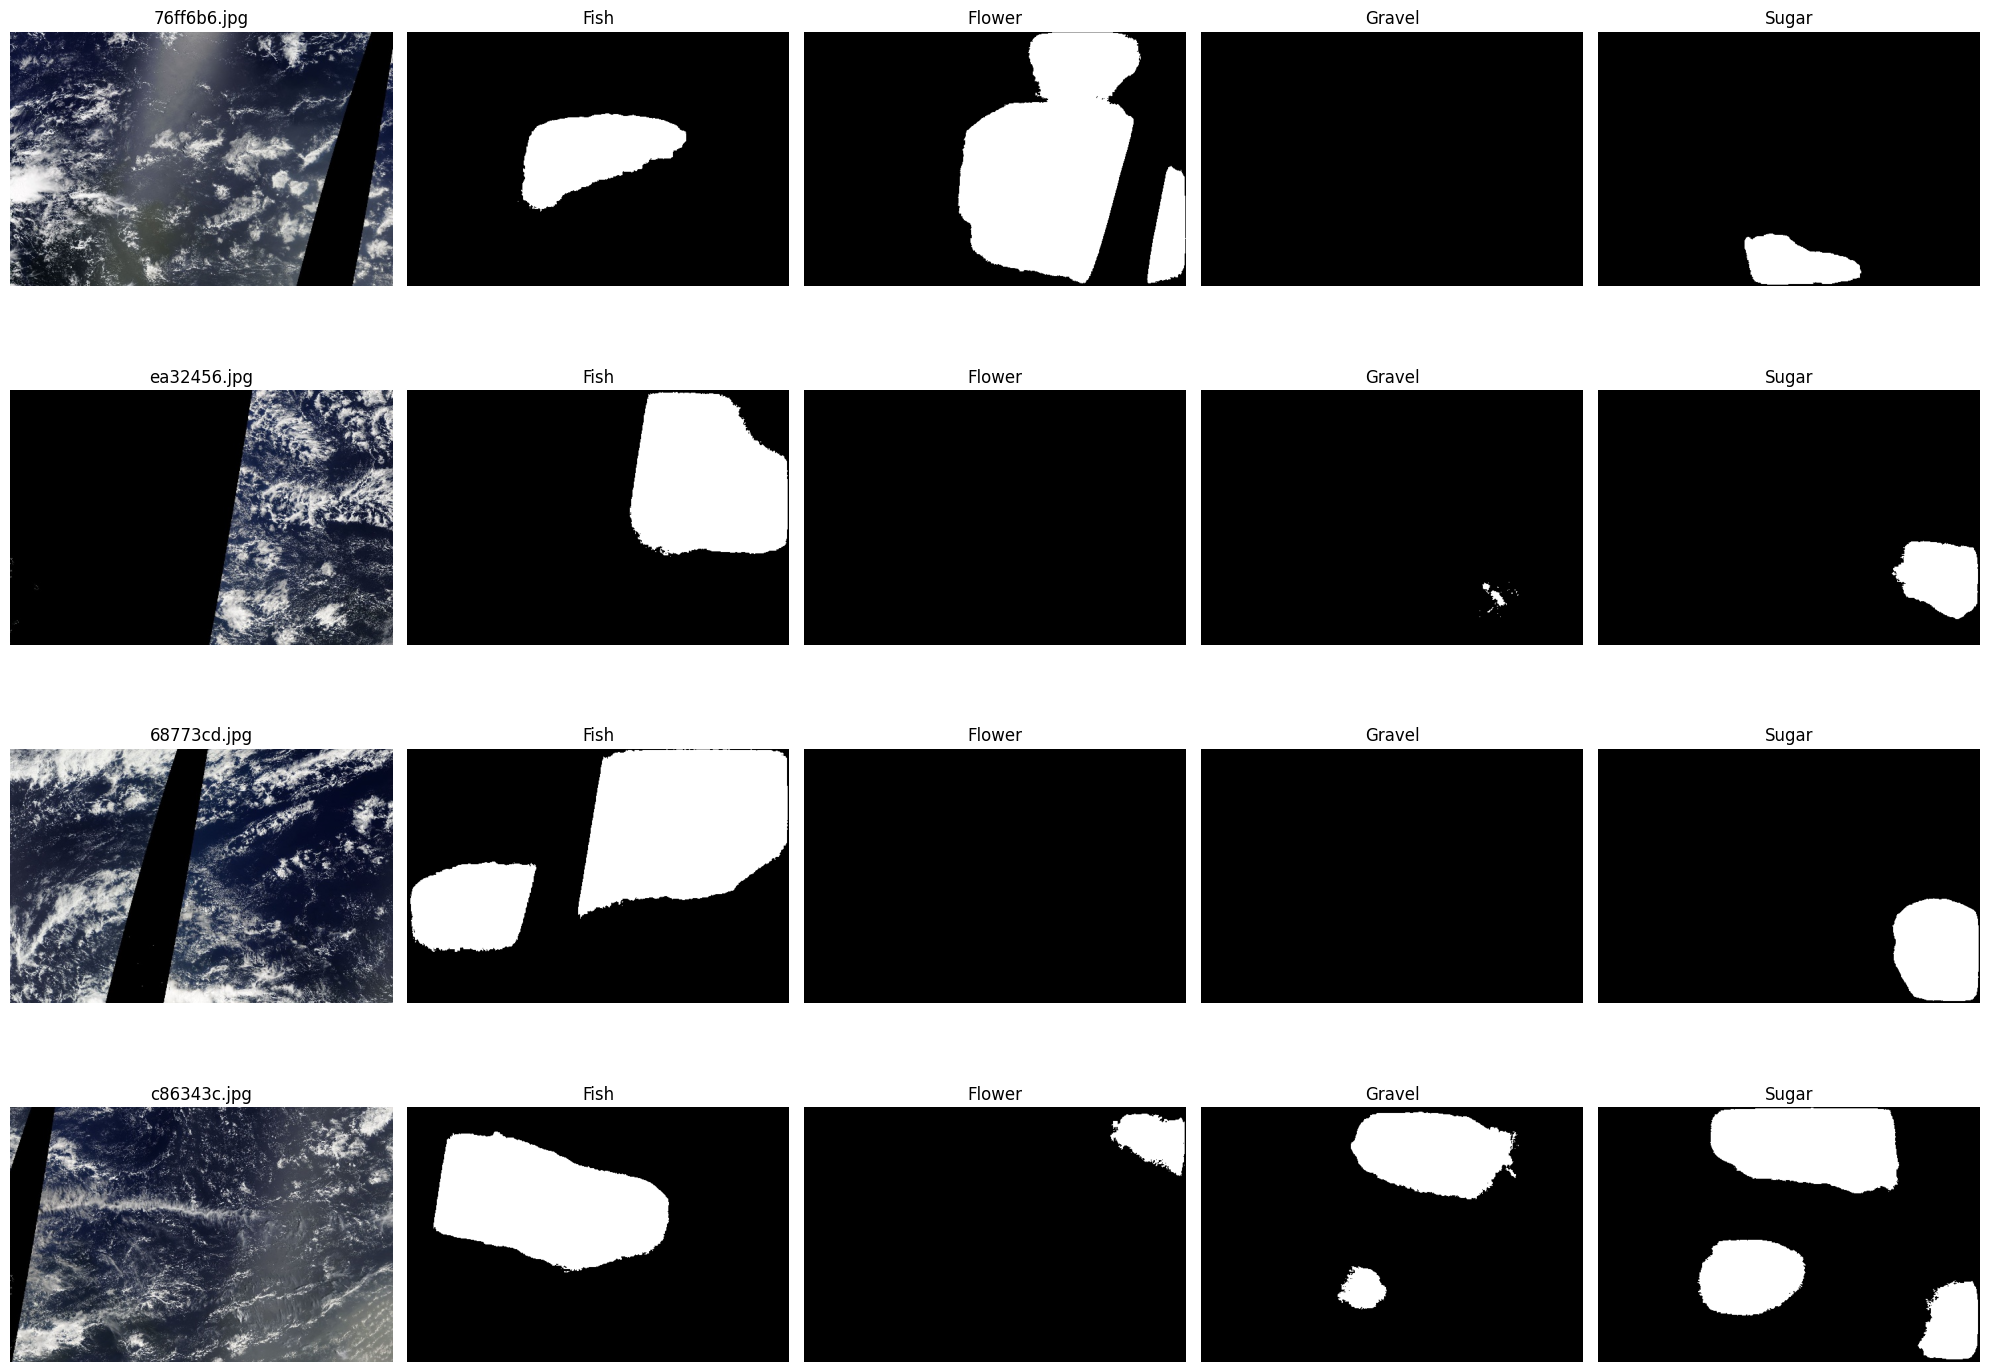

In [106]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(
    4,
    5,
    figsize=(20, 15)
)

for row in range(4):

    # Original satellite image
    image = X_test[row].cpu().numpy().transpose(1, 2, 0)

    # Undo ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax[row, 0].imshow(image)
    ax[row, 0].set_title(random_images[row])
    ax[row, 0].axis("off")

    # Fish / Flower / Gravel / Sugar
    for class_index, class_name in enumerate(CLASSES):

        mask = pred_mask[
            row,
            class_index
        ].cpu().numpy()

        ax[row, class_index + 1].imshow(
            mask,
            cmap="gray"
        )

        ax[row, class_index + 1].set_title(
            class_name
        )

        ax[row, class_index + 1].axis("off")

plt.tight_layout()
plt.show()

In [108]:
HEIGHT = 384
WIDTH = 576

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

TEST_DIR = TEST_IMAGES_DIR

THRESHOLDS = np.array([
    0.5,   # Fish
    0.5,   # Flower
    0.5,   # Gravel
    0.5    # Sugar
])

BATCH_SIZE = 4


def rle_encode(mask):

    # Flatten in the same direction used by the decoder
    pixels = mask.flatten(order="F")

    # Add zeros at beginning and end
    pixels = np.concatenate(
        [[0], pixels, [0]]
    )

    # Find changes between 0 and 1
    runs = np.where(
        pixels[1:] != pixels[:-1]
    )[0] + 1

    # Convert start/end positions to start/length
    runs[1::2] -= runs[::2]

    return " ".join(
        str(x) for x in runs
    )


test_images = sorted([
    file
    for file in os.listdir(TEST_DIR)
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("Number of test images:", len(test_images))
print(test_images[:5])

Number of test images: 3698
['002f507.jpg', '0035ae9.jpg', '0038327.jpg', '004f759.jpg', '005ba08.jpg']


# 1.Test Set Prediction

In [110]:
import os
import cv2
import numpy as np
import torch

HEIGHT = 384
WIDTH = 576

CLASSES = [
    "Fish",
    "Flower",
    "Gravel",
    "Sugar"
]

TEST_DIR = TEST_IMAGES_DIR

THRESHOLDS = np.array([
    0.5,
    0.5,
    0.5,
    0.5
])

BATCH_SIZE = 4

test_images = sorted([
    file
    for file in os.listdir(TEST_DIR)
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

print("Number of test images:", len(test_images))

model.eval()

all_predictions = []

with torch.no_grad():

    for start in range(0, len(test_images), BATCH_SIZE):

        batch_names = test_images[
            start:start + BATCH_SIZE
        ]

        batch_images = []

        for image_name in batch_names:

            image_path = os.path.join(
                TEST_DIR,
                image_name
            )

            image = cv2.imread(image_path)

            if image is None:
                raise FileNotFoundError(image_path)

            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            image = cv2.resize(
                image,
                (WIDTH, HEIGHT)
            )

            image = image.astype(
                np.float32
            ) / 255.0

            # ImageNet normalization
            mean = np.array(
                [0.485, 0.456, 0.406]
            )

            std = np.array(
                [0.229, 0.224, 0.225]
            )

            image = (
                image - mean
            ) / std

            # HWC → CHW
            image = image.transpose(
                2, 0, 1
            )

            batch_images.append(image)

        batch_images = np.stack(
            batch_images
        )

        batch_tensor = torch.tensor(
            batch_images,
            dtype=torch.float32
        ).to(device)

        logits = model(batch_tensor)

        probabilities = torch.sigmoid(
            logits
        )

        thresholds = torch.tensor(
            THRESHOLDS,
            dtype=torch.float32,
            device=device
        ).view(1, 4, 1, 1)

        predictions = (
            probabilities > thresholds
        ).cpu().numpy().astype(np.uint8)

        all_predictions.append(predictions)

        print(
            f"Processed {min(start + BATCH_SIZE, len(test_images))}"
            f"/{len(test_images)}"
        )

all_predictions = np.concatenate(
    all_predictions,
    axis=0
)

print("\nFinal prediction shape:")
print(all_predictions.shape)

Number of test images: 3698
Processed 4/3698
Processed 8/3698
Processed 12/3698
Processed 16/3698
Processed 20/3698
Processed 24/3698
Processed 28/3698
Processed 32/3698
Processed 36/3698
Processed 40/3698
Processed 44/3698
Processed 48/3698
Processed 52/3698
Processed 56/3698
Processed 60/3698
Processed 64/3698
Processed 68/3698
Processed 72/3698
Processed 76/3698
Processed 80/3698
Processed 84/3698
Processed 88/3698
Processed 92/3698
Processed 96/3698
Processed 100/3698
Processed 104/3698
Processed 108/3698
Processed 112/3698
Processed 116/3698
Processed 120/3698
Processed 124/3698
Processed 128/3698
Processed 132/3698
Processed 136/3698
Processed 140/3698
Processed 144/3698
Processed 148/3698
Processed 152/3698
Processed 156/3698
Processed 160/3698
Processed 164/3698
Processed 168/3698
Processed 172/3698
Processed 176/3698
Processed 180/3698
Processed 184/3698
Processed 188/3698
Processed 192/3698
Processed 196/3698
Processed 200/3698
Processed 204/3698
Processed 208/3698
Processed 

# 2. RLE Encoding

In [111]:
def rle_encode(mask):

    pixels = mask.flatten(order="F")

    pixels = np.concatenate(
        [[0], pixels, [0]]
    )

    runs = np.where(
        pixels[1:] != pixels[:-1]
    )[0] + 1

    runs[1::2] -= runs[::2]

    return " ".join(
        str(x) for x in runs
    )

# 3. Create Final Output

In [113]:
submission_rows = []

for image_index, image_name in enumerate(test_images):

    for class_index, class_name in enumerate(CLASSES):

        mask = all_predictions[
            image_index,
            class_index
        ]

        encoded_pixels = rle_encode(mask)

        submission_rows.append({
            "Image_Label": f"{image_name}_{class_name}",
            "EncodedPixels": encoded_pixels
        })

submission_df = pd.DataFrame(
    submission_rows
)

print("Output shape:", submission_df.shape)

print("\nFirst rows:")
print(submission_df.head())

Output shape: (14792, 2)

First rows:
          Image_Label                                      EncodedPixels
0    002f507.jpg_Fish                                                   
1  002f507.jpg_Flower                                                   
2  002f507.jpg_Gravel  405 6 412 312 730 4 738 2 743 2 781 357 1160 3...
3   002f507.jpg_Sugar  153013 1 153019 5 153026 1 153030 6 153037 1 1...
4    0035ae9.jpg_Fish  68036 5 68043 1 68417 12 68430 2 68434 3 68797...


# 4. Save Final CSV

In [114]:
OUTPUT_PATH = "/content/cloud_data/final_predictions.csv"

submission_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Final output saved to:")
print(OUTPUT_PATH)

Final output saved to:
/content/cloud_data/final_predictions.csv


In [115]:
OUTPUT_PATH = "/content/cloud_data/final_predictions.csv"

final_df = pd.read_csv(OUTPUT_PATH)

print("Output shape:", final_df.shape)
print("\nColumns:")
print(final_df.columns.tolist())

print("\nFirst 8 rows:")
print(final_df.head(8))

Output shape: (14792, 2)

Columns:
['Image_Label', 'EncodedPixels']

First 8 rows:
          Image_Label                                      EncodedPixels
0    002f507.jpg_Fish                                                NaN
1  002f507.jpg_Flower                                                NaN
2  002f507.jpg_Gravel  405 6 412 312 730 4 738 2 743 2 781 357 1160 3...
3   002f507.jpg_Sugar  153013 1 153019 5 153026 1 153030 6 153037 1 1...
4    0035ae9.jpg_Fish  68036 5 68043 1 68417 12 68430 2 68434 3 68797...
5  0035ae9.jpg_Flower                                                NaN
6  0035ae9.jpg_Gravel  523 1 536 13 887 95 991 1 993 18 1013 3 1256 1...
7   0035ae9.jpg_Sugar  30644 8 31027 14 31408 17 31790 22 32173 24 32...


In [116]:
print("Number of unique images:",
      final_df["Image_Label"].str.rsplit("_", n=1).str[0].nunique())

print("\nRows per image:")
print(
    final_df["Image_Label"]
    .str.rsplit("_", n=1)
    .str[0]
    .value_counts()
    .value_counts()
)

print("\nRows per class:")
print(
    final_df["Image_Label"]
    .str.rsplit("_", n=1)
    .str[1]
    .value_counts()
)

Number of unique images: 3698

Rows per image:
count
4    3698
Name: count, dtype: int64

Rows per class:
Image_Label
Fish      3698
Flower    3698
Gravel    3698
Sugar     3698
Name: count, dtype: int64


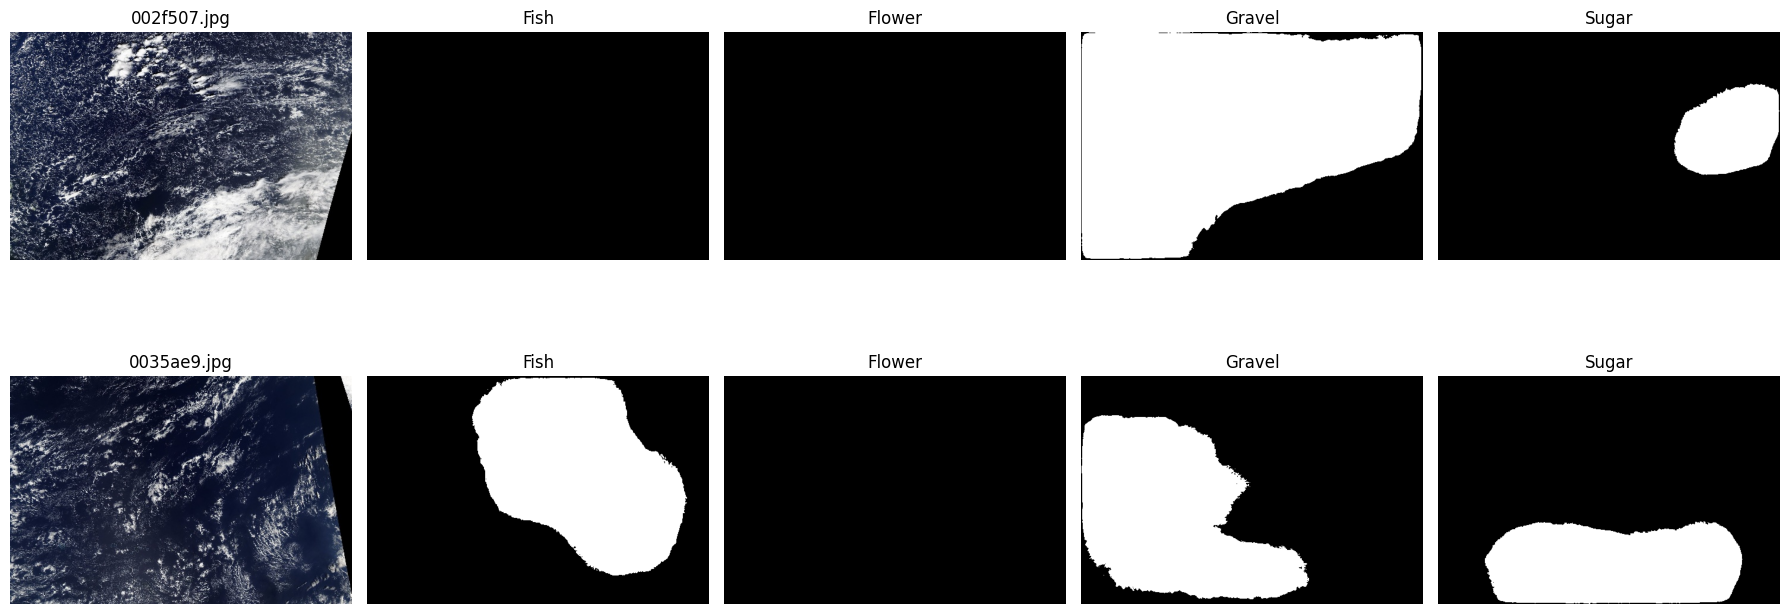

In [117]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

# Select 2 test images
selected_indices = [0, 1]

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8)
)

for row, image_index in enumerate(selected_indices):

    image_name = test_images[image_index]

    image_path = os.path.join(
        TEST_DIR,
        image_name
    )

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (576, 384)
    )

    # Original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(image_name)
    axes[row, 0].axis("off")

    # Predicted masks
    for class_index, class_name in enumerate(CLASSES):

        mask = all_predictions[
            image_index,
            class_index
        ]

        axes[row, class_index + 1].imshow(
            mask,
            cmap="gray"
        )

        axes[row, class_index + 1].set_title(
            class_name
        )

        axes[row, class_index + 1].axis("off")

plt.tight_layout()
plt.show()